In [48]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("titanic")

In [49]:
# Build a reusable function that summarizes missing data in any DataFrame :
# Missing Data Report

def missing_report(df):
    report = pd.DataFrame({
        "missing_count": df.isnull().sum(),
        "missing_percent": (df.isnull().mean() * 100).round(2),
        "dtype": df.dtypes,
    })
    return report[report["missing_count"] > 0].sort_values(
        "missing_percent", ascending=False
    )

print(missing_report(df))


             missing_count  missing_percent     dtype
deck                   688            77.22  category
age                    177            19.87   float64
embarked                 2             0.22    object
embark_town              2             0.22    object


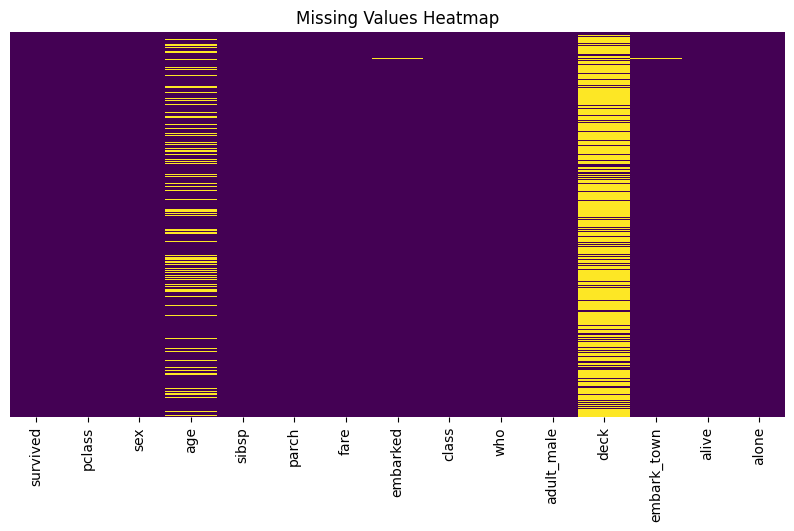

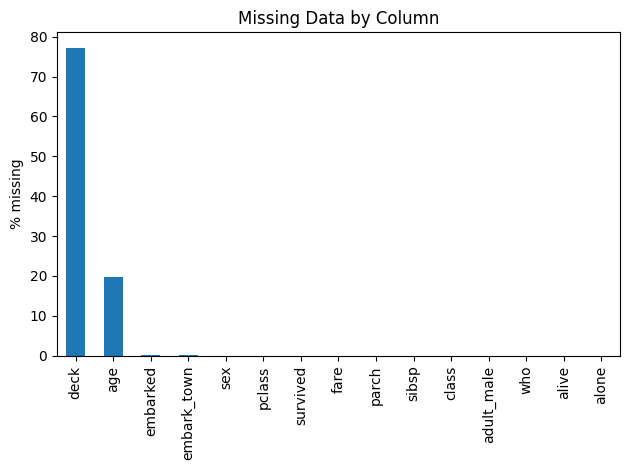

In [50]:
# A bar chart of missing_percent, and a column called suggestion that says "drop column" if missing > 50%, otherwise "impute":
# Visualize Missing Data with Seaborn

# Heatmap: yellow = missing

plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Values Heatmap")
plt.show()

# Bar chart of missing percent

(df.isnull().mean() * 100).sort_values(ascending=False).plot(kind="bar")
plt.ylabel("% missing")
plt.title("Missing Data by Column")
plt.tight_layout()
plt.show()

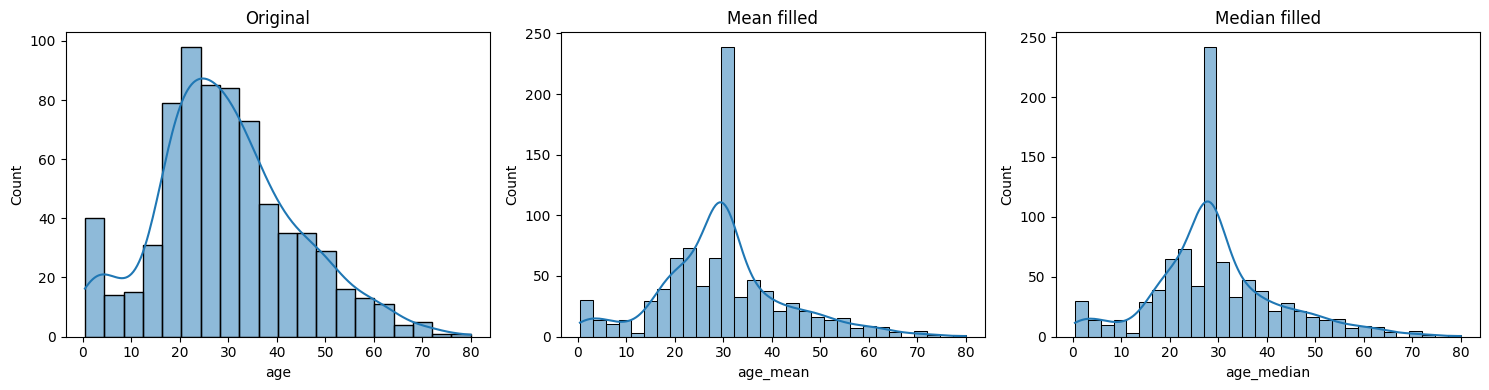

              age    age_mean  age_median
count  714.000000  891.000000  891.000000
mean    29.699118   29.699118   29.361582
std     14.526497   13.002015   13.019697
min      0.420000    0.420000    0.420000
25%     20.125000   22.000000   22.000000
50%     28.000000   29.699118   28.000000
75%     38.000000   35.000000   35.000000
max     80.000000   80.000000   80.000000


In [51]:
# See with your own eyes why mean imputation can be misleading.
# Compare Imputation Methods Visually

df["age_mean"] = df["age"].fillna(df["age"].mean())
df["age_median"] = df["age"].fillna(df["age"].median())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["age"], kde=True, ax=axes[0]).set_title("Original")
sns.histplot(df["age_mean"], kde=True, ax=axes[1]).set_title("Mean filled")
sns.histplot(df["age_median"], kde=True, ax=axes[2]).set_title("Median filled")
plt.tight_layout()
plt.show()

print(df[["age", "age_mean", "age_median"]].describe())

In [52]:
# Use group-based filling, a very common real-world technique.
# Smarter Filling with groupby

# Does age differ by passenger class?

print(df.groupby("pclass")["age"].median())

# Fill age using the median of each class

df["age_by_class"] = df["age"].fillna(
    df.groupby("pclass")["age"].transform("median")
)

# Compare with simple median

print(df[["age_median", "age_by_class"]].describe())

pclass
1    37.0
2    29.0
3    24.0
Name: age, dtype: float64
       age_median  age_by_class
count  891.000000    891.000000
mean    29.361582     29.066409
std     13.019697     13.244532
min      0.420000      0.420000
25%     22.000000     22.000000
50%     28.000000     26.000000
75%     35.000000     37.000000
max     80.000000     80.000000


deck_missing
0    0.669951
1    0.299419
Name: survived, dtype: float64


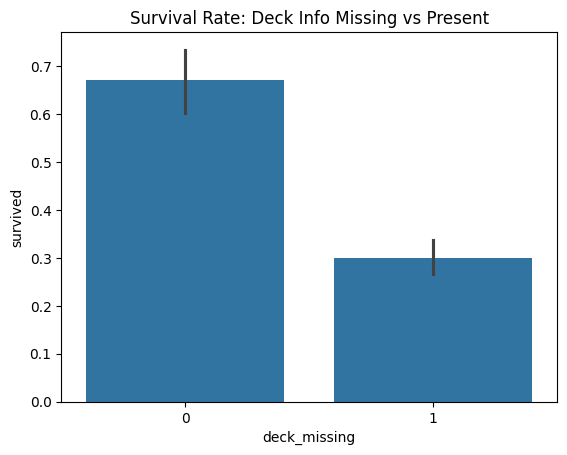

In [53]:
# "missing" can be information itself
# Does Missingness Mean Something ?

# Create a flag: was the cabin (deck) info missing?

df["deck_missing"] = df["deck"].isnull().astype(int)

# Compare survival rates

print(df.groupby("deck_missing")["survived"].mean())

sns.barplot(data=df, x="deck_missing", y="survived")
plt.title("Survival Rate: Deck Info Missing vs Present")
plt.show()

In [54]:
# Handle messy data, which is exactly what you'll see at work.
# Cleaning Hidden Missing Values

messy = pd.DataFrame({
    "name": ["Ali", "Sara", "Reza", "Mina", "Omid"],
    "age": [25, -999, 31, "N/A", 40],
    "city": ["Tehran", "", "Shiraz", "None", "Tabriz"],
})

# Replace all fake-missing values with real NaN

messy = messy.replace(["N/A", "None", "", " ", -999, "-999"], pd.NA)

# Fix the age column type

messy["age"] = pd.to_numeric(messy["age"], errors="coerce")

print(messy)
print(messy.isnull().sum())

   name   age    city
0   Ali  25.0  Tehran
1  Sara   NaN    <NA>
2  Reza  31.0  Shiraz
3  Mina   NaN    <NA>
4  Omid  40.0  Tabriz
name    0
age     2
city    2
dtype: int64


            original  ffill  bfill  interpolate
2024-01-01      20.0   20.0   20.0    20.000000
2024-01-02      21.0   21.0   21.0    21.000000
2024-01-03       NaN   21.0   25.0    22.333333
2024-01-04       NaN   21.0   25.0    23.666667
2024-01-05      25.0   25.0   25.0    25.000000
2024-01-06      26.0   26.0   26.0    26.000000
2024-01-07       NaN   26.0   28.0    27.000000
2024-01-08      28.0   28.0   28.0    28.000000
2024-01-09      29.0   29.0   29.0    29.000000
2024-01-10      30.0   30.0   30.0    30.000000


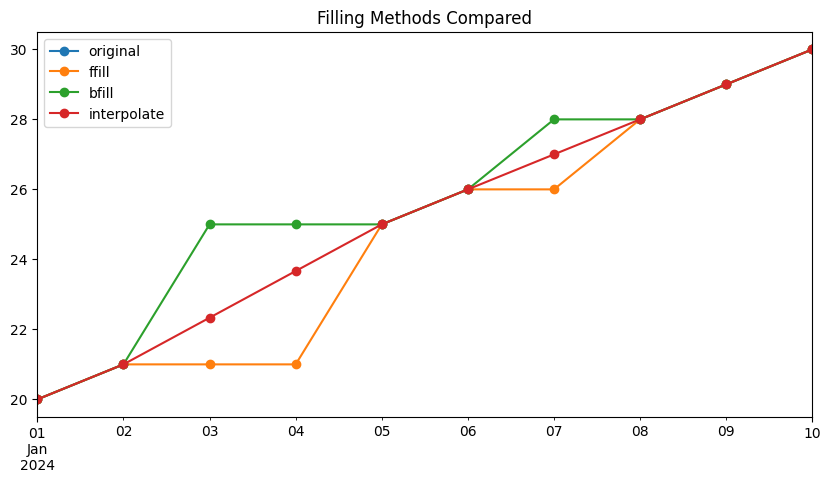

In [55]:
# Practice ffill, bfill, interpolate on simple data.
# Time Series Filling

dates = pd.date_range("2024-01-01", periods=10)
temps = pd.Series([20, 21, None, None, 25, 26, None, 28, 29, 30], index=dates)

result = pd.DataFrame({
    "original": temps,
    "ffill": temps.ffill(),
    "bfill": temps.bfill(),
    "interpolate": temps.interpolate(),
})
print(result)

result.plot(marker="o", figsize=(10, 5), title="Filling Methods Compared")
plt.show()

In [56]:
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score

df = sns.load_dataset("titanic")
df = df.drop(columns=["deck", "alive", "class", "who", "adult_male", "embark_town"])

X = df.drop(columns="survived")
y = df["survived"]

num_cols = ["age", "fare", "sibsp", "parch"]
cat_cols = ["sex", "embarked", "pclass"]

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

model = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(random_state=42)),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
scores = cross_val_score(model, X_train, y_train, cv=5, scoring="roc_auc")
print(f"CV AUC: {scores.mean():.3f} ± {scores.std():.3f}")

CV AUC: 0.847 ± 0.038


In [57]:
import numpy as np

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.metrics import mean_absolute_error


data = df[["pclass", "fare", "sibsp", "parch", "age"]].dropna().copy()
rng = np.random.default_rng(42)
mask = rng.random(len(data)) < 0.2          # حذف مصنوعی ۲۰٪ از age
data_missing = data.copy()
data_missing.loc[mask, "age"] = np.nan

imputers = {
    "mean": SimpleImputer(strategy="mean"),
    "median": SimpleImputer(strategy="median"),
    "knn": KNNImputer(n_neighbors=5),
    "iterative": IterativeImputer(random_state=0),
}
for name, imp in imputers.items():
    filled = pd.DataFrame(imp.fit_transform(data_missing), columns=data.columns)
    mae = mean_absolute_error(data.loc[mask, "age"], filled.loc[mask, "age"])
    print(f"{name:10s} MAE = {mae:.2f}")

mean       MAE = 12.18
median     MAE = 12.32
knn        MAE = 11.12
iterative  MAE = 10.29


In [58]:
df["age"] = df.groupby(["pclass", "sex"])["age"].transform(
    lambda s: s.fillna(s.median())
)

In [59]:
from sklearn.ensemble import HistGradientBoostingClassifier

X_enc = pd.get_dummies(X, columns=["sex", "embarked"], dtype=float)
hgb = HistGradientBoostingClassifier(random_state=42)
print(cross_val_score(hgb, X_enc, y, cv=5, scoring="roc_auc").mean())
# بدون هیچ imputation، با NaN ها مستقیم

0.8638294824402546
